# Mod_C
## Week 5

### Project: Cardiovascular Disease

This notebook continues the cardiovascular disease project developed in Module B.

Week 5 applies Support Vector Machines (SVMs) to the Statlog Heart Disease and Framingham Heart
Study datasets.

The analysis focuses on:

- Support vector classification
- Decision boundaries and margins
- Support vectors
- Feature scaling
- Linear, polynomial, and Gaussian/RBF kernels
- The kernel trick
- SVM regularization using the parameter `C`

As in Week 4, the models will address binary cardiovascular outcomes.

For Statlog, the goal is to predict whether heart disease is present using `target`.

For Framingham, the goal is to predict whether an individual develops coronary heart disease within
10 years using `TenYearCHD`.

Model performance will be evaluated using accuracy, precision, recall, F1 score, ROC AUC, confusion
matrices, and the number of support vectors.

## Support Vector Machines

A Support Vector Machine is a classification method that attempts to separate classes using a decision
boundary called a hyperplane.

Rather than finding just any separating boundary, SVM attempts to create a boundary with a large margin.

The margin is the distance between the decision boundary and the closest observations on either side.
A larger margin can help a model generalize better to unseen data because the classes are separated with
more room between them.

The observations closest to the decision boundary are called support vectors. These observations are
especially important because they help determine the position of the SVM decision boundary.

SVMs can use different kernel functions when a simple linear boundary is not sufficient. This notebook
will compare linear, polynomial, and Gaussian/RBF kernels.

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    make_scorer
)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [3]:
from google.colab import files

uploaded = files.upload()

Saving preprocessed_framingham.csv to preprocessed_framingham.csv
Saving preprocessed_heart_disease.csv to preprocessed_heart_disease.csv


In [4]:
heart = pd.read_csv(
    "/content/preprocessed_heart_disease.csv"
)

framingham = pd.read_csv(
    "/content/preprocessed_framingham.csv"
)

print(
    "Heart Disease dataset shape:",
    heart.shape
)

print(
    "Framingham dataset shape:",
    framingham.shape
)

Heart Disease dataset shape: (270, 14)
Framingham dataset shape: (4238, 16)


## Outcome Distribution

The same binary outcomes used in Week 4 will be used for SVM classification.

Statlog is relatively balanced between the two classes, while Framingham contains substantially fewer
positive TenYearCHD cases.

This class imbalance is important because accuracy alone can be misleading. Therefore, precision, recall,
F1 score, and ROC AUC will also be used when evaluating SVM performance.

In [5]:
print("Statlog target distribution:")
print(
    heart["target"].value_counts()
)

print("\nStatlog target percentages:")
print(
    heart["target"].value_counts(
        normalize=True
    ).round(3)
)

print("\nFramingham TenYearCHD distribution:")
print(
    framingham["TenYearCHD"].value_counts()
)

print("\nFramingham TenYearCHD percentages:")
print(
    framingham["TenYearCHD"].value_counts(
        normalize=True
    ).round(3)
)

Statlog target distribution:
target
0    150
1    120
Name: count, dtype: int64

Statlog target percentages:
target
0    0.556
1    0.444
Name: proportion, dtype: float64

Framingham TenYearCHD distribution:
TenYearCHD
0    3594
1     644
Name: count, dtype: int64

Framingham TenYearCHD percentages:
TenYearCHD
0    0.848
1    0.152
Name: proportion, dtype: float64


## Predictor Setup

The predictor structure from Week 4 will be retained so that SVM performance can later be compared
with logistic regression using the same cardiovascular information.

Continuous clinical measurements will be treated as numerical features.

Binary indicators will remain binary.

Statlog variables whose numerical values represent categories rather than continuous quantities will be
one-hot encoded. Education will similarly be treated as categorical in Framingham.

In [6]:

# STATLOG

heart_numeric_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

heart_binary_features = [
    "sex",
    "fbs",
    "exang"
]

heart_categorical_features = [
    "cp",
    "restecg",
    "slope",
    "ca",
    "thal"
]

heart_features = (
    heart_numeric_features
    + heart_binary_features
    + heart_categorical_features
)


# FRAMINGHAM

framingham_numeric_features = [
    "age",
    "cigsPerDay",
    "totChol",
    "sysBP",
    "diaBP",
    "BMI",
    "heartRate",
    "glucose"
]

framingham_binary_features = [
    "male",
    "currentSmoker",
    "BPMeds",
    "prevalentStroke",
    "prevalentHyp",
    "diabetes"
]

framingham_categorical_features = [
    "education"
]

framingham_features = (
    framingham_numeric_features
    + framingham_binary_features
    + framingham_categorical_features
)

print(
    "Statlog predictors:",
    len(heart_features)
)

print(
    "Framingham predictors:",
    len(framingham_features)
)

Statlog predictors: 13
Framingham predictors: 15


## Train-Test Separation

The datasets will be divided into training and testing sets before any feature scaling or model selection
is performed.

A stratified split will preserve approximately the same proportion of positive and negative cases in each set.

All preprocessing, kernel comparisons, and hyperparameter selection will be learned using the training data.

The held-out test set will not be used to fit transformations or select SVM hyperparameters. It will be used
only to evaluate prespecified modeling approaches on unseen observations.

In [8]:
# STATLOG

heart_model_data = heart[
    heart_features + ["target"]
].dropna()

X_heart = heart_model_data[
    heart_features
]

y_heart = heart_model_data[
    "target"
]

X_heart_train, X_heart_test, y_heart_train, y_heart_test = train_test_split(
    X_heart,
    y_heart,
    test_size=0.20,
    random_state=42,
    stratify=y_heart
)


# FRAMINGHAM

framingham_model_data = framingham[
    framingham_features + ["TenYearCHD"]
].dropna()

X_framingham = framingham_model_data[
    framingham_features
]

y_framingham = framingham_model_data[
    "TenYearCHD"
]

X_framingham_train, X_framingham_test, y_framingham_train, y_framingham_test = train_test_split(
    X_framingham,
    y_framingham,
    test_size=0.20,
    random_state=42,
    stratify=y_framingham
)

print(
    "Statlog training size:",
    X_heart_train.shape
)

print(
    "Statlog testing size:",
    X_heart_test.shape
)

print(
    "Framingham training size:",
    X_framingham_train.shape
)

print(
    "Framingham testing size:",
    X_framingham_test.shape
)

Statlog training size: (216, 13)
Statlog testing size: (54, 13)
Framingham training size: (3390, 15)
Framingham testing size: (848, 15)


## Feature Scaling for SVM

Feature scaling is particularly important for SVM because the model's decision boundary and margin depend
on distances between observations.

If one feature has values in the hundreds while another feature ranges only from 0 to 1, the larger-scale
feature may have an excessive influence on the model simply because of its units.

Standardization transforms continuous predictors so that they are measured on comparable scales.

To demonstrate the effect of scaling, a linear SVM with no numerical scaling will first be compared with
the same linear SVM using standardized numerical predictors.

Scaling will be performed inside the modeling pipeline so that the scaler learns only from the training data.

In [56]:
def create_svm_preprocessor(
    numeric_features,
    binary_features,
    categorical_features,
    scaling_method
):

    if scaling_method == "standard":

        numeric_transformer = StandardScaler()

    elif scaling_method == "none":

        numeric_transformer = "passthrough"

    else:

        raise ValueError(
            "Scaling method must be 'none' or 'standard'."
        )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_transformer,
                numeric_features
            ),
            (
                "binary",
                "passthrough",
                binary_features
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                categorical_features
            )
        ]
    )

    return preprocessor

In [57]:
def get_cv_classification_metrics(
    pipeline,
    X_train,
    y_train
):

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scoring = {
        "accuracy": "accuracy",

        "precision": make_scorer(
            precision_score,
            zero_division=0
        ),

        "recall": make_scorer(
            recall_score,
            zero_division=0
        ),

        "f1": "f1",

        "roc_auc": "roc_auc"
    }

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    return {
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC AUC": scores["test_roc_auc"].mean()
    }

### Linear SVM: Scaled vs Unscaled Features

A linear SVM with `C = 1` will be evaluated with and without standardization using stratified
5-fold cross-validation on the training data.

All other model settings will remain unchanged so that the effect of feature scaling can be examined
directly without using the held-out test set.

In [59]:
def compare_svm_scaling(
    X_train,
    y_train,
    numeric_features,
    binary_features,
    categorical_features,
    dataset_name
):

    results = []
    fitted_models = {}

    for scaling_method in [
        "none",
        "standard"
    ]:

        preprocessor = create_svm_preprocessor(
            numeric_features,
            binary_features,
            categorical_features,
            scaling_method
        )

        pipeline = Pipeline([
            (
                "preprocessing",
                preprocessor
            ),
            (
                "svm",
                SVC(
                    kernel="linear",
                    C=1.0
                )
            )
        ])

        cv_metrics = get_cv_classification_metrics(
            pipeline,
            X_train,
            y_train
        )

        # Fit on all training data only so that
        # support-vector counts can be examined.
        pipeline.fit(
            X_train,
            y_train
        )

        svm_model = pipeline.named_steps[
            "svm"
        ]

        results.append({
            "Scaling": scaling_method,

            **cv_metrics,

            "Total Support Vectors": np.sum(
                svm_model.n_support_
            )
        })

        fitted_models[
            scaling_method
        ] = pipeline

    results_df = pd.DataFrame(
        results
    ).round(3)

    print(dataset_name)
    display(results_df)

    return results_df, fitted_models

### Statlog Feature Scaling Comparison

In [60]:
heart_svm_scaling_results, heart_svm_scaling_models = compare_svm_scaling(
    X_heart_train,
    y_heart_train,
    heart_numeric_features,
    heart_binary_features,
    heart_categorical_features,
    "Statlog Heart Disease Dataset"
)

Statlog Heart Disease Dataset


,Scaling,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC AUC,Total Support Vectors
0,none,0.815,0.817,0.771,0.788,0.884,79
1,standard,0.824,0.827,0.782,0.799,0.887,78


#### Statlog Scaling Interpretation

Standardization produced a modest improvement in Statlog SVM performance.

Without scaling, the linear SVM achieved a cross-validation accuracy of 0.815, recall of 0.771,
F1 score of 0.788, and ROC AUC of 0.884.

After standardization, cross-validation accuracy increased to 0.824, recall increased to 0.782,
F1 increased to 0.799, and ROC AUC increased slightly to 0.887.

The number of support vectors also changed only slightly, from 79 without scaling to 78 after
standardization.

These results suggest that standardization provided a small benefit for Statlog, although the difference
was not large. Standardization will therefore be retained for the remaining SVM analyses because SVM
depends on distances between observations and can be sensitive to differences in feature scale.

### Framingham Feature Scaling Comparison

In [61]:
framingham_svm_scaling_results, framingham_svm_scaling_models = compare_svm_scaling(
    X_framingham_train,
    y_framingham_train,
    framingham_numeric_features,
    framingham_binary_features,
    framingham_categorical_features,
    "Framingham Heart Study Dataset"
)

Framingham Heart Study Dataset


,Scaling,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC AUC,Total Support Vectors
0,none,0.848,0.133,0.004,0.008,0.721,1040
1,standard,0.847,0.050,0.002,0.004,0.606,1259


#### Framingham Scaling Interpretation

Feature scaling did not improve the ordinary linear SVM for Framingham.

Without standardization, the model achieved a cross-validation accuracy of 0.848 and ROC AUC of
0.721. However, recall was only 0.004 and F1 was only 0.008.

After standardization, accuracy remained approximately the same at 0.847, while recall decreased to
0.002 and F1 decreased to 0.004. ROC AUC also decreased to 0.606.

These results show that feature scaling alone does not solve the main Framingham classification problem.
The model continues to predict almost entirely the majority negative class because positive TenYearCHD
cases are relatively uncommon.

Standardization will still be used in later SVM analyses so that features are measured on comparable
scales, but the Framingham results indicate that class imbalance requires additional attention.

## The Kernel Trick

A linear SVM attempts to separate classes using a linear decision boundary.

However, some datasets cannot be separated effectively with a straight decision boundary.

The kernel trick allows SVM to model more complicated relationships without explicitly constructing every
feature in a potentially high-dimensional transformed space.

Three kernels will be compared:

### Linear Kernel

The linear kernel creates a flat decision boundary in the predictor space.

### Polynomial Kernel

A polynomial kernel allows interactions and nonlinear polynomial relationships among predictors.

A second-degree polynomial kernel will be used for the initial comparison.

### Gaussian / RBF Kernel

The Gaussian kernel, called the Radial Basis Function (RBF) kernel in scikit-learn, allows flexible nonlinear
decision boundaries based on distances between observations.

All kernel comparisons will use standardized numerical features and `C = 1`. Stratified 5-fold
cross-validation on the training data will be used so that the held-out test set does not influence
the kernel comparison.

In [62]:
def compare_svm_kernels(
    X_train,
    y_train,
    numeric_features,
    binary_features,
    categorical_features,
    dataset_name
):

    kernel_settings = [

        (
            "Linear",
            {
                "kernel": "linear"
            }
        ),

        (
            "Polynomial Degree 2",
            {
                "kernel": "poly",
                "degree": 2,
                "coef0": 0
            }
        ),

        (
            "Gaussian / RBF",
            {
                "kernel": "rbf",
                "gamma": "scale"
            }
        )
    ]

    results = []
    fitted_models = {}

    for kernel_name, kernel_parameters in kernel_settings:

        preprocessor = create_svm_preprocessor(
            numeric_features,
            binary_features,
            categorical_features,
            "standard"
        )

        svm = SVC(
            C=1.0,
            **kernel_parameters
        )

        pipeline = Pipeline([
            (
                "preprocessing",
                preprocessor
            ),
            (
                "svm",
                svm
            )
        ])

        cv_metrics = get_cv_classification_metrics(
            pipeline,
            X_train,
            y_train
        )

        # Fit on the complete training set only
        # to examine support-vector counts.
        pipeline.fit(
            X_train,
            y_train
        )

        fitted_svm = pipeline.named_steps[
            "svm"
        ]

        results.append({
            "Kernel": kernel_name,

            **cv_metrics,

            "Support Vectors Class 0":
                fitted_svm.n_support_[0],

            "Support Vectors Class 1":
                fitted_svm.n_support_[1],

            "Total Support Vectors":
                np.sum(
                    fitted_svm.n_support_
                )
        })

        fitted_models[
            kernel_name
        ] = pipeline

    results_df = pd.DataFrame(
        results
    ).round(3)

    print(dataset_name)
    display(results_df)

    return results_df, fitted_models

### Statlog Kernel Comparison

In [63]:
heart_kernel_results, heart_kernel_models = compare_svm_kernels(
    X_heart_train,
    y_heart_train,
    heart_numeric_features,
    heart_binary_features,
    heart_categorical_features,
    "Statlog Heart Disease Dataset"
)

Statlog Heart Disease Dataset


,Kernel,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC AUC,Support Vectors Class 0,Support Vectors Class 1,Total Support Vectors
0,Linear,0.824,0.827,0.782,0.799,0.887,40,38,78
1,Polynomial Degree 2,0.847,0.860,0.791,0.822,0.902,57,53,110
2,Gaussian / RBF,0.833,0.831,0.792,0.807,0.902,65,63,128


#### Statlog Kernel Interpretation

The nonlinear kernels improved cross-validation performance compared with the linear SVM.

The linear kernel achieved a cross-validation F1 score of 0.799 and ROC AUC of 0.887.

The degree-2 polynomial kernel achieved the highest F1 score at 0.822 and increased ROC AUC to
0.902. The Gaussian/RBF kernel also achieved an ROC AUC of 0.902, but its F1 score was slightly
lower at 0.807.

The polynomial model used 110 support vectors compared with 78 for the linear model, while the RBF
model used 128.

These results suggest that the relationship between the Statlog predictors and heart-disease outcome is not
entirely linear. Allowing a nonlinear decision boundary provided a modest improvement, with the degree-2
polynomial kernel producing the strongest overall cross-validation results.

### Framingham Kernel Comparison

In [64]:
framingham_kernel_results, framingham_kernel_models = compare_svm_kernels(
    X_framingham_train,
    y_framingham_train,
    framingham_numeric_features,
    framingham_binary_features,
    framingham_categorical_features,
    "Framingham Heart Study Dataset"
)

Framingham Heart Study Dataset


,Kernel,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC AUC,Support Vectors Class 0,Support Vectors Class 1,Total Support Vectors
0,Linear,0.847,0.050,0.002,0.004,0.606,744,515,1259
1,Polynomial Degree 2,0.849,0.867,0.010,0.019,0.663,588,513,1101
2,Gaussian / RBF,0.850,0.770,0.021,0.041,0.625,885,515,1400


#### Framingham Kernel Interpretation

Changing the kernel produced some differences in Framingham discrimination, but none of the ordinary
unbalanced SVM models successfully identified many positive CHD cases.

The linear kernel achieved a cross-validation F1 score of only 0.004 and recall of 0.002.

The degree-2 polynomial kernel improved ROC AUC from 0.606 to 0.663, but recall remained only 0.010.
The Gaussian/RBF kernel increased recall slightly to 0.021 and F1 to 0.041.

Therefore, nonlinear kernels alone were not sufficient to address the Framingham classification problem.
The models continued to favor the much larger negative class.

The polynomial kernel nevertheless demonstrated the strongest ROC AUC of the three kernels, suggesting
that nonlinear relationships may contain useful information even though class imbalance still prevents
effective positive-class classification without additional adjustments.

## Support Vectors

Support vectors are the training observations closest to the decision boundary or observations that lie within
or violate the margin.

These observations are especially important because they help determine the position of the SVM decision
boundary.

The kernel-comparison tables report the number of support vectors from each class.


### Support Vector Interpretation

The number of support vectors differed across kernels and datasets.

For Statlog, the linear SVM used 78 support vectors, the degree-2 polynomial SVM used 110, and the
RBF SVM used 128. The nonlinear models therefore relied on more training observations to define their
decision boundaries.

For Framingham, the models required substantially more support vectors because the dataset is much larger
and the classes are more difficult to separate. The linear model used 1,259 support vectors, the polynomial
model used 1,101, and the RBF model used 1,400.

A larger number of support vectors does not automatically indicate better or worse performance. Instead, it
shows how many training observations contribute directly to defining the margin and decision boundary.

The results demonstrate that the observations nearest to the classification boundary play an important role
in determining the final SVM model.

## SVM Regularization and the Parameter C

SVM must balance two goals:

1. Creating a large margin between the classes.
2. Correctly classifying the training observations.

The regularization parameter `C` controls this tradeoff.

A smaller value of `C` applies stronger regularization. The model is more willing to tolerate training errors
in exchange for a wider and potentially more generalizable margin.

A larger value of `C` places greater emphasis on correctly classifying the training data, which can produce a
narrower and more complex boundary.

Several values of `C` will be tested using a standardized linear SVM to examine how regularization affects
training performance, cross-validation performance, and the number of support vectors.

Cross-validation will use only the training data so that the held-out test set does not influence the
regularization comparison.

In [65]:
def analyze_svm_c_values(
    X_train,
    y_train,
    numeric_features,
    binary_features,
    categorical_features,
    dataset_name
):

    c_values = [
        0.01,
        0.1,
        1,
        10,
        100
    ]

    results = []

    for c_value in c_values:

        preprocessor = create_svm_preprocessor(
            numeric_features,
            binary_features,
            categorical_features,
            "standard"
        )

        pipeline = Pipeline([
            (
                "preprocessing",
                preprocessor
            ),
            (
                "svm",
                SVC(
                    kernel="linear",
                    C=c_value
                )
            )
        ])

        cv_metrics = get_cv_classification_metrics(
            pipeline,
            X_train,
            y_train
        )

        # Fit on the complete training set only
        # to inspect training fit and support vectors.
        pipeline.fit(
            X_train,
            y_train
        )

        train_predictions = pipeline.predict(
            X_train
        )

        fitted_svm = pipeline.named_steps[
            "svm"
        ]

        results.append({
            "C": c_value,

            "Training Accuracy": accuracy_score(
                y_train,
                train_predictions
            ),

            "CV Accuracy":
                cv_metrics["CV Accuracy"],

            "CV Recall":
                cv_metrics["CV Recall"],

            "CV F1":
                cv_metrics["CV F1"],

            "CV ROC AUC":
                cv_metrics["CV ROC AUC"],

            "Total Support Vectors":
                np.sum(
                    fitted_svm.n_support_
                )
        })

    results_df = pd.DataFrame(
        results
    ).round(3)

    print(dataset_name)
    display(results_df)

    return results_df

### Statlog Regularization Comparison

In [66]:
heart_c_results = analyze_svm_c_values(
    X_heart_train,
    y_heart_train,
    heart_numeric_features,
    heart_binary_features,
    heart_categorical_features,
    "Statlog Heart Disease Dataset"
)

Statlog Heart Disease Dataset


,C,Training Accuracy,CV Accuracy,CV Recall,CV F1,CV ROC AUC,Total Support Vectors
0,0.01,0.838,0.805,0.677,0.758,0.898,150
1,0.10,0.866,0.829,0.782,0.802,0.904,100
2,1.00,0.866,0.824,0.782,0.799,0.887,78
3,10.00,0.884,0.805,0.761,0.776,0.888,73
4,100.00,0.884,0.801,0.751,0.769,0.890,72


#### Statlog Regularization Interpretation

Changing `C` affected both model complexity and cross-validation performance.

At the smallest value, `C = 0.01`, the Statlog model used 150 support vectors and achieved a
cross-validation F1 score of 0.758.

Performance improved as `C` increased to 0.1, where F1 reached its highest value of 0.802 and ROC AUC
reached 0.904.

Increasing `C` further did not improve generalization. At `C = 10` and `C = 100`, training accuracy
increased to 0.884, but cross-validation F1 decreased to 0.776 and 0.769 respectively.

The number of support vectors also decreased from 150 at `C = 0.01` to 72 at `C = 100`.

This illustrates the SVM regularization tradeoff. Very small `C` values permit a softer boundary with more
support vectors, while large `C` values place greater emphasis on fitting the training observations. For
Statlog, moderate regularization generalized better than either extreme.

### Framingham Regularization Comparison

In [67]:
framingham_c_results = analyze_svm_c_values(
    X_framingham_train,
    y_framingham_train,
    framingham_numeric_features,
    framingham_binary_features,
    framingham_categorical_features,
    "Framingham Heart Study Dataset"
)

Framingham Heart Study Dataset


,C,Training Accuracy,CV Accuracy,CV Recall,CV F1,CV ROC AUC,Total Support Vectors
0,0.01,0.848,0.848,0.000,0.000,0.600,1068
1,0.10,0.848,0.848,0.000,0.000,0.616,1113
2,1.00,0.848,0.847,0.002,0.004,0.606,1259
3,10.00,0.848,0.847,0.004,0.007,0.559,1486
4,100.00,0.848,0.847,0.004,0.007,0.679,1276


#### Framingham Regularization Interpretation

Changing `C` alone did not solve the Framingham class-imbalance problem.

Across all tested values of `C`, training accuracy remained approximately 0.848 and cross-validation
accuracy remained approximately 0.847 to 0.848.

However, recall remained between 0.000 and 0.004, and F1 remained between 0.000 and 0.007.

This means that the apparently high accuracy was largely produced by predicting the majority negative class.
Simply increasing or decreasing the SVM regularization strength did not make the model meaningfully better at
identifying individuals who developed CHD.

The result shows that `C` controls the margin-versus-training-error tradeoff, but it cannot by itself correct
a severe imbalance between outcome classes.

### Effect of C on Classification Performance

The following plots show how cross-validation F1 score changes as the SVM regularization parameter
increases.

Because the tested values of `C` span several orders of magnitude, the horizontal axis is shown on a
logarithmic scale.

Cross-validation is performed using only the training data so that the held-out test set remains
separate from this regularization analysis.

In [68]:
def plot_c_performance(
    results,
    dataset_name
):

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        results["C"],
        results["CV F1"],
        marker="o"
    )

    plt.xscale(
        "log"
    )

    plt.xlabel(
        "C"
    )

    plt.ylabel(
        "5-Fold CV F1 Score"
    )

    plt.title(
        f"{dataset_name}: Effect of C on SVM Performance"
    )

    plt.show()

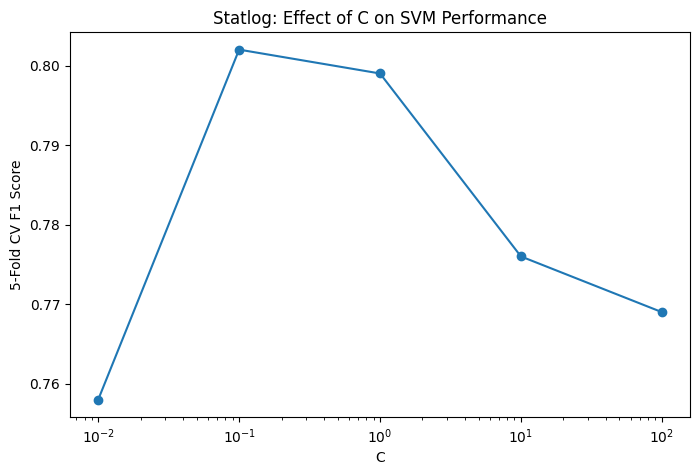

In [69]:
plot_c_performance(
    heart_c_results,
    "Statlog"
)

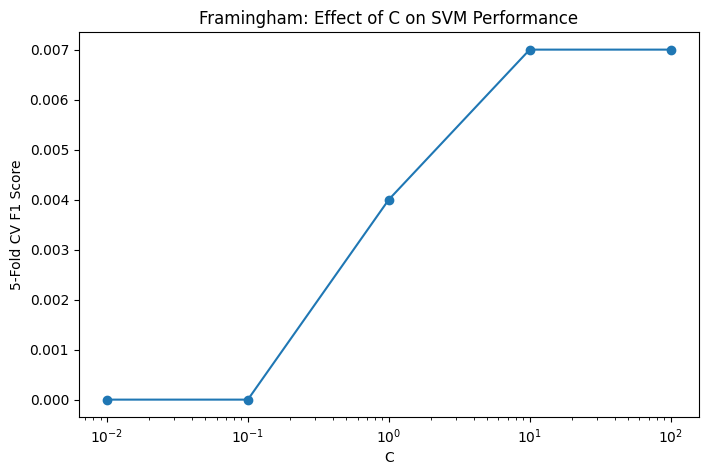

In [70]:
plot_c_performance(
    framingham_c_results,
    "Framingham"
)

### Effect of C on Support Vectors

The number of support vectors will also be compared across values of `C`.

Changing regularization can change which observations lie on or within the margin and therefore how many
training observations act as support vectors.

In [42]:
def plot_c_support_vectors(
    results,
    dataset_name
):

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        results["C"],
        results["Total Support Vectors"],
        marker="o"
    )

    plt.xscale(
        "log"
    )

    plt.xlabel(
        "C"
    )

    plt.ylabel(
        "Number of Support Vectors"
    )

    plt.title(
        f"{dataset_name}: C vs Support Vectors"
    )

    plt.show()

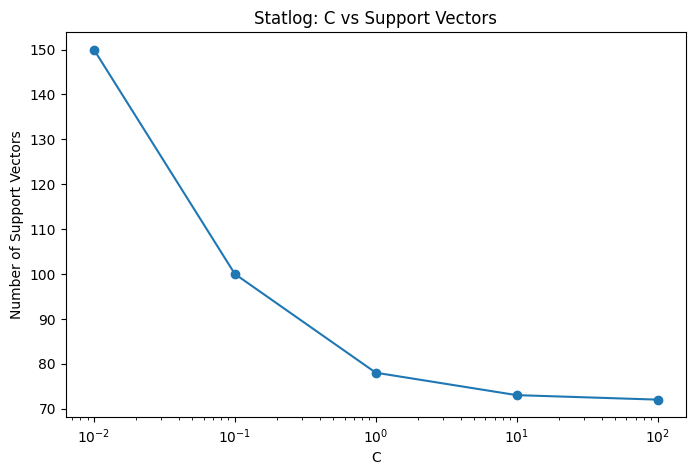

In [71]:
plot_c_support_vectors(
    heart_c_results,
    "Statlog"
)

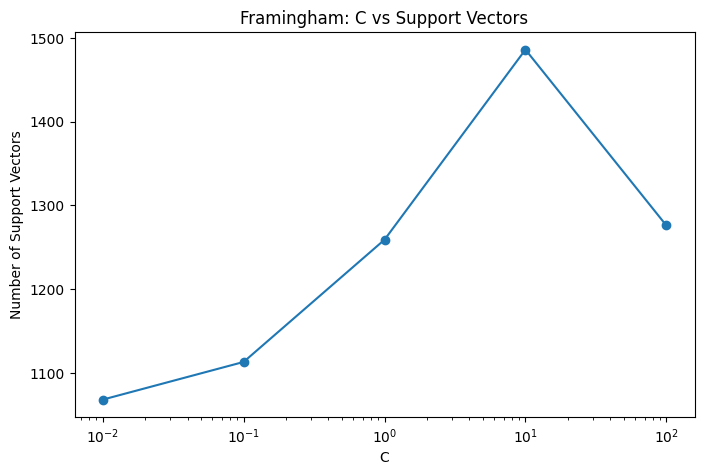

In [72]:
plot_c_support_vectors(
    framingham_c_results,
    "Framingham"
)

### Regularization and Support Vector Summary

The Statlog results show a relatively clear relationship between `C` and the number of support vectors.
As `C` increased, fewer observations were required as support vectors, while training accuracy generally
increased.

However, the highest training accuracy did not correspond to the best cross-validation performance. This
shows why selecting `C` based only on training fit could lead to overfitting.

The Framingham relationship was less consistent because severe class imbalance dominated the behavior of
the ordinary linear SVM.

Overall, these experiments demonstrate that `C` should be selected using validation performance rather than
simply maximizing training accuracy or minimizing the number of support vectors.

## Cross-Validated SVM Model Selection

The previous analyses examined scaling, kernels, and regularization separately.

A final SVM strategy will now be selected using stratified 5-fold cross-validation on the training data.

The search will compare:

- Linear kernel
- Polynomial kernel
- Gaussian/RBF kernel
- Multiple values of `C`
- Ordinary and balanced class weighting
- Polynomial degrees 2 and 3

F1 score will be used as the primary cross-validation metric.

This is especially appropriate for Framingham because the positive CHD class is relatively uncommon and
accuracy alone can favor the majority negative class.

The held-out test set will not be used during hyperparameter selection.

In [45]:
def tune_svm_model(
    X_train,
    X_test,
    y_train,
    y_test,
    numeric_features,
    binary_features,
    categorical_features,
    dataset_name
):

    preprocessor = create_svm_preprocessor(
        numeric_features,
        binary_features,
        categorical_features,
        "standard"
    )

    pipeline = Pipeline([
        (
            "preprocessing",
            preprocessor
        ),
        (
            "svm",
            SVC()
        )
    ])

    c_values = [
        0.01,
        0.1,
        1,
        10,
        100
    ]

    parameter_grid = [

        # Linear SVM
        {
            "svm__kernel": [
                "linear"
            ],

            "svm__C":
                c_values,

            "svm__class_weight": [
                None,
                "balanced"
            ]
        },

        # Polynomial SVM
        {
            "svm__kernel": [
                "poly"
            ],

            "svm__C":
                c_values,

            "svm__degree": [
                2,
                3
            ],

            "svm__coef0": [
                0
            ],

            "svm__gamma": [
                "scale"
            ],

            "svm__class_weight": [
                None,
                "balanced"
            ]
        },

        # Gaussian / RBF SVM
        {
            "svm__kernel": [
                "rbf"
            ],

            "svm__C":
                c_values,

            "svm__gamma": [
                "scale"
            ],

            "svm__class_weight": [
                None,
                "balanced"
            ]
        }
    ]

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    search = GridSearchCV(
        pipeline,
        param_grid=parameter_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1
    )

    search.fit(
        X_train,
        y_train
    )

    predictions = search.predict(
        X_test
    )

    decision_scores = search.decision_function(
        X_test
    )

    best_svm = search.best_estimator_.named_steps[
        "svm"
    ]

    results = pd.DataFrame([{

        "Dataset":
            dataset_name,

        "Best Kernel":
            search.best_params_[
                "svm__kernel"
            ],

        "Best C":
            search.best_params_[
                "svm__C"
            ],

        "Best Class Weight":
            search.best_params_[
                "svm__class_weight"
            ],

        "Best Degree":
            search.best_params_.get(
                "svm__degree",
                np.nan
            ),

        "CV F1":
            search.best_score_,

        "Accuracy":
            accuracy_score(
                y_test,
                predictions
            ),

        "Precision":
            precision_score(
                y_test,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_test,
                predictions,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_test,
                predictions,
                zero_division=0
            ),

        "ROC AUC":
            roc_auc_score(
                y_test,
                decision_scores
            ),

        "Support Vectors Class 0":
            best_svm.n_support_[0],

        "Support Vectors Class 1":
            best_svm.n_support_[1],

        "Total Support Vectors":
            np.sum(
                best_svm.n_support_
            )

    }]).round(3)

    print(
        "Best parameters:"
    )

    print(
        search.best_params_
    )

    display(
        results
    )

    return search, results

### Tuned Statlog SVM

In [46]:
heart_tuned_svm, heart_tuned_svm_results = tune_svm_model(
    X_heart_train,
    X_heart_test,
    y_heart_train,
    y_heart_test,
    heart_numeric_features,
    heart_binary_features,
    heart_categorical_features,
    "Statlog"
)

Best parameters:
{'svm__C': 1, 'svm__class_weight': 'balanced', 'svm__coef0': 0, 'svm__degree': 2, 'svm__gamma': 'scale', 'svm__kernel': 'poly'}


,Dataset,Best Kernel,Best C,Best Class Weight,Best Degree,CV F1,Accuracy,Precision,Recall,F1,ROC AUC,Support Vectors Class 0,Support Vectors Class 1,Total Support Vectors
0,Statlog,poly,1,balanced,2,0.83,0.815,0.75,0.875,0.808,0.899,64,52,116


#### Tuned Statlog SVM Interpretation

Stratified 5-fold cross-validation selected a degree-2 polynomial kernel with `C = 1` and balanced class
weighting for Statlog.

The selected model achieved a cross-validation F1 score of 0.830.

On the held-out test set, it achieved:

- Accuracy: 0.815
- Precision: 0.750
- Recall: 0.875
- F1 score: 0.808
- ROC AUC: 0.899

The final model used 116 support vectors, including 64 from class 0 and 52 from class 1.

The high recall indicates that the model identified most positive heart-disease cases, while ROC AUC near
0.90 indicates strong discrimination between the two classes.

The selection of a polynomial kernel is also consistent with the earlier kernel comparison, which suggested
that nonlinear relationships improved Statlog classification.

### Tuned Framingham SVM

In [47]:
framingham_tuned_svm, framingham_tuned_svm_results = tune_svm_model(
    X_framingham_train,
    X_framingham_test,
    y_framingham_train,
    y_framingham_test,
    framingham_numeric_features,
    framingham_binary_features,
    framingham_categorical_features,
    "Framingham"
)

Best parameters:
{'svm__C': 0.1, 'svm__class_weight': 'balanced', 'svm__coef0': 0, 'svm__degree': 2, 'svm__gamma': 'scale', 'svm__kernel': 'poly'}


,Dataset,Best Kernel,Best C,Best Class Weight,Best Degree,CV F1,Accuracy,Precision,Recall,F1,ROC AUC,Support Vectors Class 0,Support Vectors Class 1,Total Support Vectors
0,Framingham,poly,0.1,balanced,2,0.396,0.722,0.256,0.434,0.322,0.691,2251,415,2666


#### Tuned Framingham SVM Interpretation

For Framingham, cross-validation selected a degree-2 polynomial kernel with `C = 0.1` and balanced
class weighting.

The selected model achieved a cross-validation F1 score of 0.396.

On the held-out test set, the model achieved:

- Accuracy: 0.722
- Precision: 0.256
- Recall: 0.434
- F1 score: 0.322
- ROC AUC: 0.691

Although the overall accuracy is lower than the approximately 85% accuracy obtained by the earlier
unbalanced SVM models, the tuned model is substantially more useful for identifying positive CHD cases.

Balanced class weighting changes the importance assigned to classification errors from the minority class.
As a result, the final model sacrifices some majority-class accuracy in order to detect substantially more
patients who actually develop CHD.

The final model used 2,666 support vectors, indicating that a large portion of the training observations
contributed to defining the classification boundary.

## Tuned SVM Confusion Matrices

Confusion matrices will be used to examine the types of errors produced by the final cross-validated SVM
models.

For cardiovascular classification, false negatives are particularly important because they represent patients
who truly belong to the positive cardiovascular outcome class but were classified as negative.

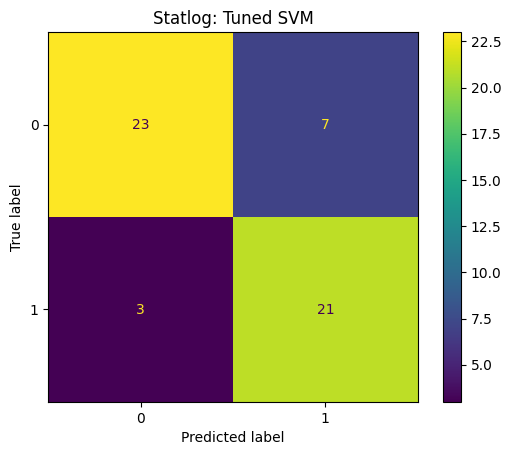

In [48]:
ConfusionMatrixDisplay.from_estimator(
    heart_tuned_svm.best_estimator_,
    X_heart_test,
    y_heart_test
)

plt.title(
    "Statlog: Tuned SVM"
)

plt.show()

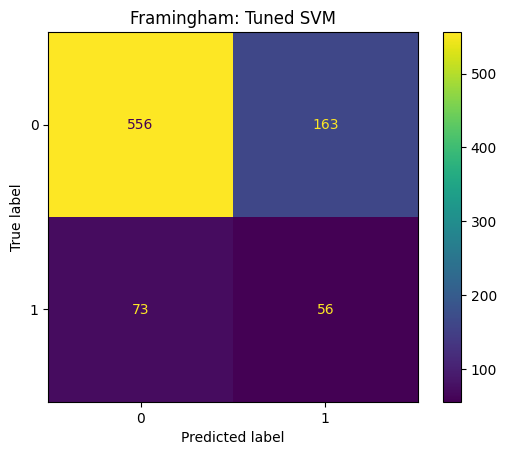

In [49]:
ConfusionMatrixDisplay.from_estimator(
    framingham_tuned_svm.best_estimator_,
    X_framingham_test,
    y_framingham_test
)

plt.title(
    "Framingham: Tuned SVM"
)

plt.show()

### Tuned Confusion Matrix Interpretation

The tuned Statlog SVM correctly classified 23 negative cases and 21 positive cases. It produced 7 false
positives and only 3 false negatives.

This is consistent with its high recall of 0.875: only a small number of actual heart-disease cases were missed.

The tuned Framingham SVM correctly classified 556 negative cases and 56 positive cases. It produced
163 false positives and 73 false negatives.

Compared with an ordinary unbalanced classifier that strongly favors the majority class, balanced weighting
allows the SVM to identify substantially more positive CHD cases. The tradeoff is a larger number of false
positives.

For a cardiovascular risk-screening problem, this tradeoff may be more useful than achieving high accuracy by
predicting almost everyone as negative.

## Tuned SVM ROC Curves

ROC curves evaluate how effectively the final SVM decision scores separate positive and negative cases across
many possible classification thresholds.

ROC AUC values closer to 1 indicate stronger discrimination between the two outcome classes.

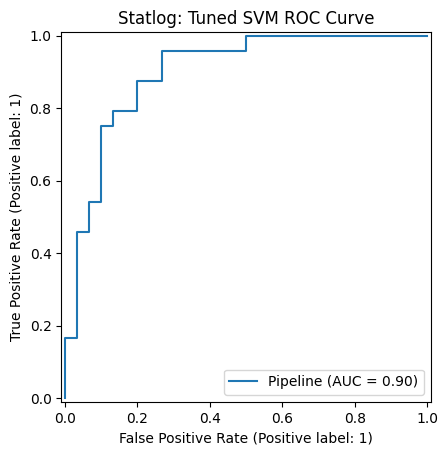

In [50]:
RocCurveDisplay.from_estimator(
    heart_tuned_svm.best_estimator_,
    X_heart_test,
    y_heart_test
)

plt.title(
    "Statlog: Tuned SVM ROC Curve"
)

plt.show()

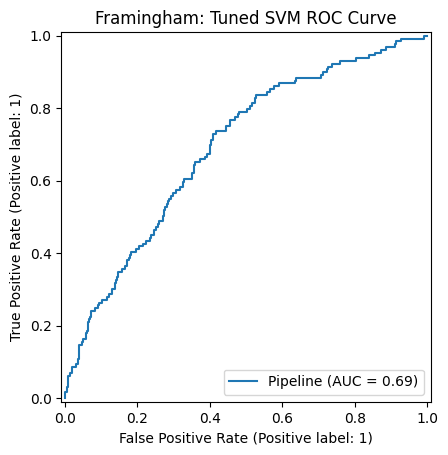

In [51]:
RocCurveDisplay.from_estimator(
    framingham_tuned_svm.best_estimator_,
    X_framingham_test,
    y_framingham_test
)

plt.title(
    "Framingham: Tuned SVM ROC Curve"
)

plt.show()

### ROC Interpretation

The tuned Statlog SVM achieved an ROC AUC of 0.899, indicating strong ability to rank positive
heart-disease cases above negative cases across different classification thresholds.

The tuned Framingham SVM achieved a lower ROC AUC of 0.691. This indicates moderate discrimination,
but substantially more overlap between the positive and negative classes than in Statlog.

These results reinforce that Framingham is the more difficult classification problem. Its larger sample size
does not automatically make prediction easier because the positive outcome is rare and the available predictors
do not cleanly separate the two groups.

## Week 5 Final SVM Results

The table below summarizes the held-out test performance of the final cross-validated SVM models for both
cardiovascular datasets.

In [52]:
week5_summary = pd.concat(
    [
        heart_tuned_svm_results,
        framingham_tuned_svm_results
    ],
    ignore_index=True
)

display(
    week5_summary
)

,Dataset,Best Kernel,Best C,Best Class Weight,Best Degree,CV F1,Accuracy,Precision,Recall,F1,ROC AUC,Support Vectors Class 0,Support Vectors Class 1,Total Support Vectors
0,Statlog,poly,1.0,balanced,2,0.830,0.815,0.750,0.875,0.808,0.899,64,52,116
1,Framingham,poly,0.1,balanced,2,0.396,0.722,0.256,0.434,0.322,0.691,2251,415,2666


## Metrics and Hyperparameter Tuning

Several metrics were used because classification performance cannot be described adequately by accuracy alone.

- **Accuracy** measures the proportion of all predictions that are correct.
- **Precision** measures how often predicted positive cases are truly positive.
- **Recall** measures how many actual positive cases are successfully identified.
- **F1 score** balances precision and recall.
- **ROC AUC** evaluates how effectively the model ranks positive cases above negative cases across different
  classification thresholds.

F1 score was used as the primary GridSearchCV selection metric because the Framingham outcome is imbalanced
and identifying positive cardiovascular cases is important.

The main SVM hyperparameters evaluated were:

- **Kernel:** controls the type of decision boundary.
- **C:** controls the tradeoff between creating a wide margin and correctly classifying training observations.
- **Degree:** controls polynomial complexity when a polynomial kernel is used.
- **Class weight:** controls whether classification errors from the minority and majority classes receive equal
  importance.

Five-fold stratified cross-validation was used on the training data to select the final hyperparameters before
the selected models were evaluated on the held-out test sets.

## Avoiding Overfitting

Several techniques were used to reduce the risk of overfitting.

First, the datasets were separated into training and held-out testing sets before model development.

Second, feature scaling, kernel comparisons, and regularization experiments were performed using only the
training data and stratified cross-validation rather than repeatedly choosing models based on test-set results.

Third, the regularization parameter `C` was tuned using cross-validation. This is important because very large
values of `C` can encourage the SVM to fit training observations too aggressively, while very small values may
produce excessive underfitting.

Finally, the final kernel and hyperparameters were selected using GridSearchCV on the training data before a
single held-out evaluation.

The Statlog `C` experiment demonstrates the value of this approach. Training accuracy increased at larger
values of `C`, while cross-validation F1 decreased, showing that greater training fit did not necessarily
produce better generalization.

## Expected and Unexpected Findings

Several results were consistent with expectations.

Standardization modestly improved the linear Statlog SVM, which is reasonable because SVM calculations are
sensitive to feature scale.

Nonlinear kernels also improved Statlog cross-validation performance. The degree-2 polynomial kernel achieved
the strongest F1 score, suggesting that heart-disease classification contains useful relationships that are not
completely linear.

The most notable result was Framingham. Changing feature scaling, kernel type, or `C` alone did not prevent
ordinary SVM models from overwhelmingly predicting the majority negative class.

Only when balanced class weighting was included during final model selection did recall become substantially
more meaningful.

This demonstrates that model complexity alone cannot compensate for severe outcome imbalance. The structure
of the dataset itself must be considered when designing the modeling strategy.

## Relationship to Previous Analysis

Previous exploratory analysis identified several cardiovascular variables associated with heart-disease risk,
including age, blood pressure, cholesterol, exercise-related measures, BMI, glucose, smoking, and related
clinical factors.

Week 4 showed that logistic regression classified Statlog effectively but struggled with the minority positive
class in Framingham unless class weighting was introduced.

Week 5 produced a similar broader pattern. Statlog was again comparatively easy to classify, while Framingham
remained substantially more difficult because TenYearCHD is strongly imbalanced.

The SVM analysis adds an important new finding: Statlog benefits modestly from a nonlinear polynomial decision
boundary, suggesting that some useful cardiovascular relationships may not be captured completely by a linear
classifier.

For Framingham, nonlinear kernels alone were not sufficient. Class weighting remained more important than
simply increasing model complexity.

## When SVMs and Different Kernels Are Appropriate

A linear SVM is appropriate when the classes can be separated reasonably well using a linear decision boundary.

Polynomial or Gaussian/RBF kernels are useful when the relationship between predictors and classes is nonlinear
and a straight boundary is insufficient.

The polynomial kernel can capture structured nonlinear relationships and interactions, while the RBF kernel
provides a more flexible nonlinear boundary based on distances between observations.

The regularization parameter `C` should be tuned rather than chosen arbitrarily. Smaller values allow more
training errors in exchange for a wider margin, while larger values place greater emphasis on correctly
classifying training observations.

For Statlog, a degree-2 polynomial kernel provided the strongest cross-validation performance.

For Framingham, kernel choice alone was insufficient because class imbalance dominated model behavior. Balanced
class weighting therefore became an important component of the final SVM strategy.

## Optimal SVM Modeling Strategy

The two datasets require different SVM strategies.

For Statlog, the data are relatively balanced and nonlinear kernels provided a modest improvement over a linear
decision boundary. Cross-validation selected a standardized degree-2 polynomial SVM with `C = 1` and balanced
class weighting. The final model maintained strong recall and ROC AUC on unseen data.

For Framingham, the primary challenge is class imbalance. Scaling, nonlinear kernels, and changes to `C` did
not independently solve the minority-class problem. The final strategy therefore combines standardization, a
degree-2 polynomial kernel, stronger regularization with `C = 0.1`, and balanced class weighting.

This strategy sacrifices some overall accuracy in exchange for substantially greater sensitivity to positive CHD
cases.

Therefore, the optimal SVM strategy depends not only on which kernel produces the highest score but also on the
class distribution, the consequences of different prediction errors, and the intended purpose of the model.

# Week 5

Week 5 applied Support Vector Machines, feature scaling, the kernel trick, support-vector analysis, and SVM
regularization to the Statlog Heart Disease and Framingham Heart Study datasets.

For Statlog, standardization modestly improved linear SVM performance. Nonlinear kernels provided additional
benefit, with a degree-2 polynomial kernel achieving the strongest cross-validation F1 score among the initial
kernel comparisons.

The `C` experiment demonstrated the regularization tradeoff. Moderate values produced stronger cross-validation
performance than very small or very large values, while high training accuracy at large `C` values did not
translate into better generalization.

Final cross-validation selected a degree-2 polynomial SVM with `C = 1` and balanced class weighting. On the
held-out test set, the model achieved 0.815 accuracy, 0.875 recall, an F1 score of 0.808, and ROC AUC of
0.899.

Framingham remained the more difficult classification problem. Ordinary SVM models achieved high accuracy while
identifying almost none of the positive CHD cases. Neither scaling, kernel selection, nor changes to `C` alone
resolved this problem.

The final Framingham model therefore used balanced class weighting together with a degree-2 polynomial kernel
and `C = 0.1`. It achieved 0.434 recall, an F1 score of 0.322, and ROC AUC of 0.691 on the held-out test set.

Overall, the analysis demonstrates that SVM performance depends on the interaction between feature scale, decision
boundary complexity, regularization, and the structure of the outcome classes. Nonlinear decision boundaries were
useful for Statlog, while addressing class imbalance was more important for Framingham.

## AI Use Disclosure

ChatGPT was used as an assistive tool to generate the code for the functions defined and then to help organize and articulate formal written interpretations after the
analysis had been performed and the models had been run. The underlying dataset analysis, model execution,
outputs, and numerical results were generated in the Jupyter Notebook and then interpreted with AI assistance
for clarity and presentation.